# **Oasis Infobyte Internship — Data Science**

# **Maragathavalli C S**

# **Task 1: Iris Flower Classification**

**Objective:** Train a machine learning classification model to identify the species of an Iris flower (Setosa, Versicolor, or Virginica) from its physical measurements.

Tech Stack: Python, scikit-learn, pandas, matplotlib, seaborn, Jupyter Notebook.

Dataset: Iris dataset provided by sklearn.datasets.load_iris().

Models: Logistic Regression, K-Nearest Neighbors, Decision Tree, and Random Forest.

Evaluation Metrics: Accuracy, confusion matrix, precision, recall, and F1-score.

**Import libraries for data manipulation, visualization, and machine learning**

In [17]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


**Load the Iris dataset**

In [18]:

# Load Iris directly from scikit-learn
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = pd.Series(
    iris.target,
    name="species_id"
)

# Create a combined DataFrame for EDA
df = X.copy()
df["species_id"] = y
df["species"] = df["species_id"].map(
    dict(enumerate(iris.target_names))
)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Dataset shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species_id,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


**Dataset overview**

In [19]:

# Display dataset dimensions
print("\nDataset shape:")
print(df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Display data types
print("\nData types:")
print(df.dtypes)

# Display the number of samples per species
print("\nSpecies distribution:")
print(df["species"].value_counts())


Dataset shape:
(150, 6)

Column names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species_id', 'species']

Data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species_id             int64
species               object
dtype: object

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


**Exploratory Data Analysis (EDA)**

In [20]:
print("Dataset dimensions:", df.shape)

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(X.describe())

print("\nSpecies distribution:")
display(df["species"].value_counts())

Dataset dimensions: (150, 6)

Column data types:
sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species_id             int64
species               object
dtype: object

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species_id           0
species              0
dtype: int64

Duplicate rows: 1

Descriptive statistics:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Species distribution:


,count
species,
setosa,50
versicolor,50
virginica,50


**Species distribution visualization**

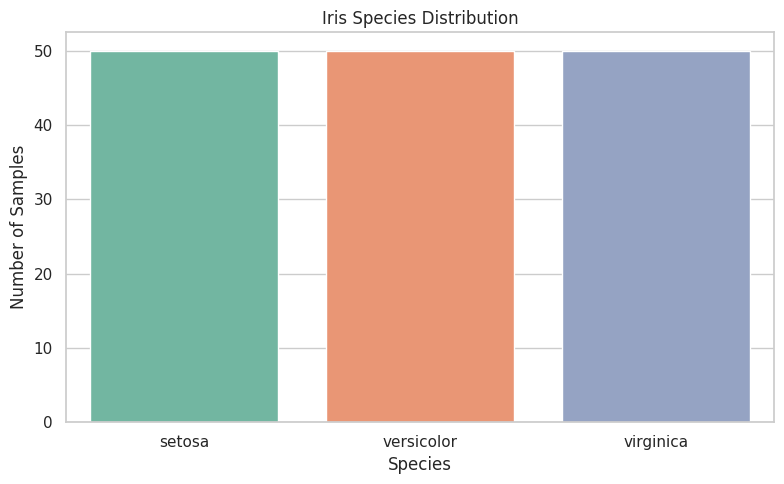

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="species",
    hue="species",
    order=iris.target_names,
    palette="Set2",
    legend=False
)

plt.title("Iris Species Distribution")
plt.xlabel("Species")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

**Pairplot**

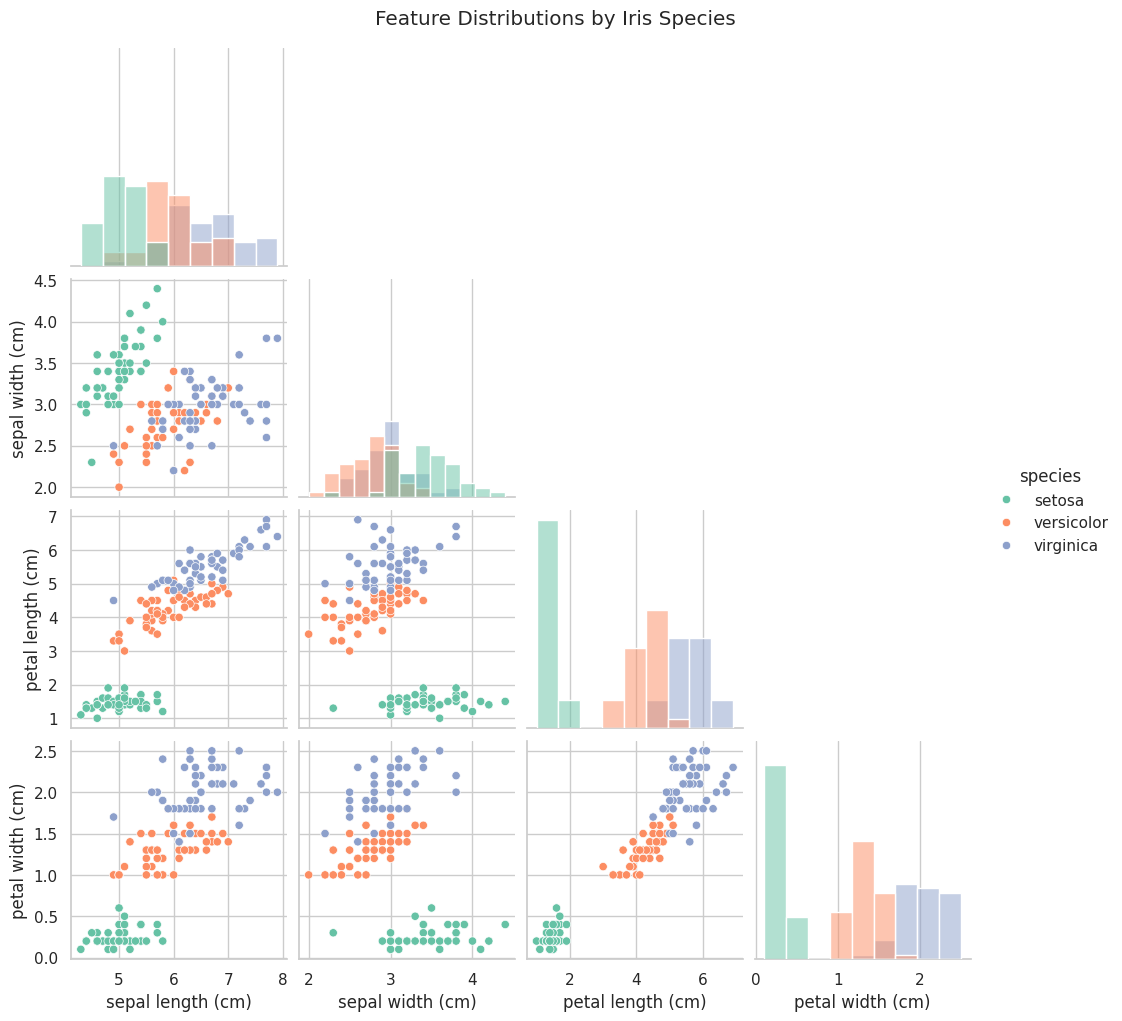

In [22]:
sns.pairplot(
    df,
    vars=iris.feature_names,
    hue="species",
    palette="Set2",
    diag_kind="hist",
    corner=True
)

plt.suptitle(
    "Feature Distributions by Iris Species",
    y=1.02
)

plt.show()

**Box plots for each feature**

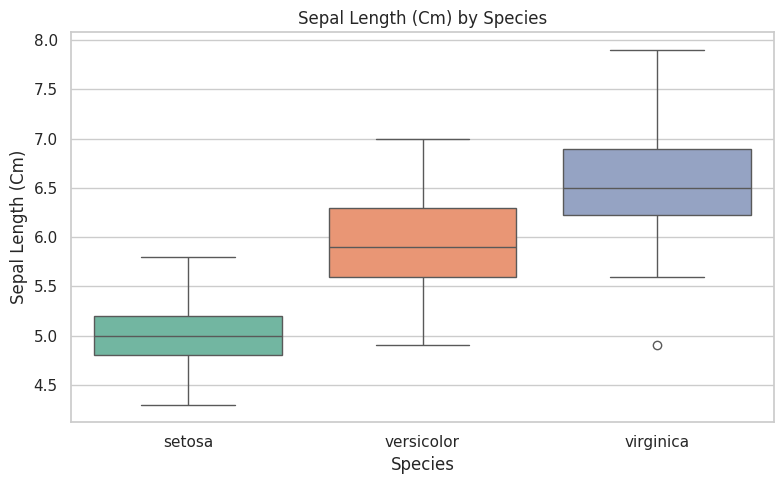

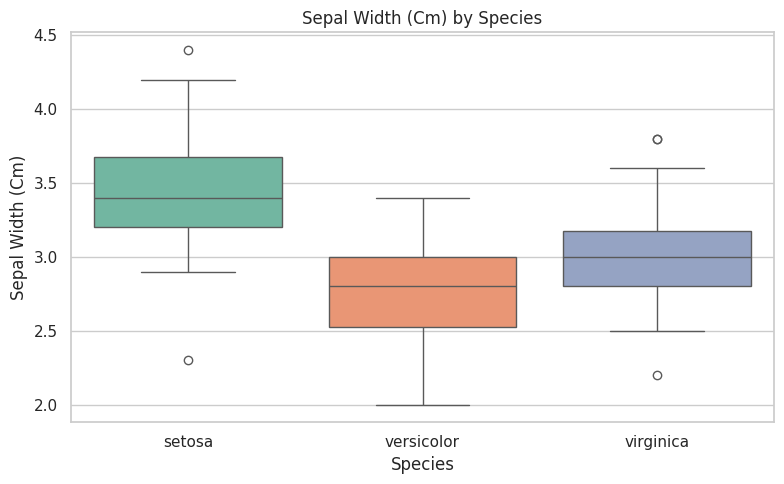

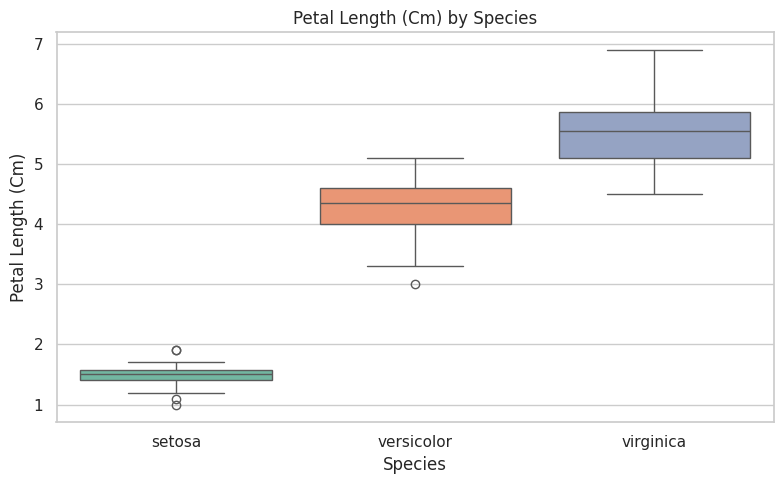

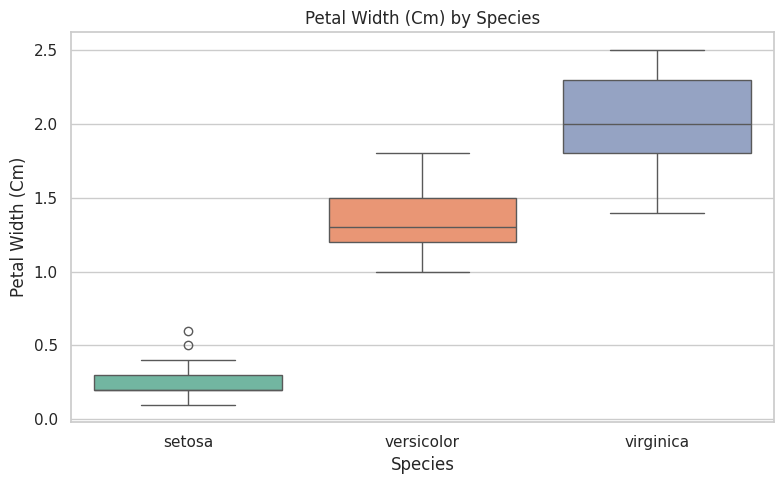

In [23]:
# Create box plots for all four numerical features

for feature in iris.feature_names:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="species",
        y=feature,
        hue="species",
        palette="Set2",
        legend=False
    )

    plt.title(f"{feature.title()} by Species")
    plt.xlabel("Species")
    plt.ylabel(feature.title())
    plt.tight_layout()
    plt.show()

**Correlation heatmap**

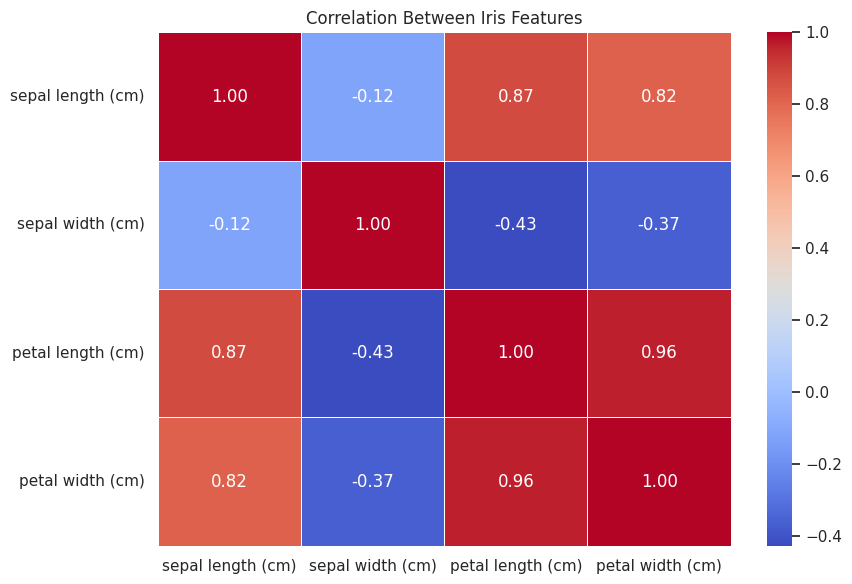

In [24]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Iris Features")
plt.tight_layout()
plt.show()

**Feature selection discussion**


The Iris dataset contains four numerical features:

1. **Sepal length (cm)**
2. **Sepal width (cm)**
3. **Petal length (cm)**
4. **Petal width (cm)**

All four features will initially be used to train the classification models.

**Feature selection discussion:**

- Petal length and petal width are generally highly discriminative features because their distributions differ considerably across Iris species.
- Setosa is particularly easy to distinguish using petal measurements.
- Sepal length and sepal width also provide useful information, but their distributions can overlap between Versicolor and Virginica.
- The pairplot and box plots help visually identify these differences.

The correlation heatmap and visualizations will be used to support this discussion. No feature is removed before the initial model comparison.

**Train-test split**

In [25]:
# Split the data into training and testing sets

# Keep the test set separate from model tuning
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining species counts:")
print(y_train.map(dict(enumerate(iris.target_names))).value_counts())

print("\nTesting species counts:")
print(y_test.map(dict(enumerate(iris.target_names))).value_counts())

Training samples: 120
Testing samples: 30

Training species counts:
species_id
setosa        40
virginica     40
versicolor    40
Name: count, dtype: int64

Testing species counts:
species_id
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


**Define and tune seven models**

In [26]:
# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define models and their hyperparameter grids
model_grids = {
    "Logistic Regression": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=3000))
        ]),
        {
            "model__C": [0.1, 1, 10, 100]
        }
    ),

    "K-Nearest Neighbors": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier())
        ]),
        {
            "model__n_neighbors": [3, 5, 7, 9, 11],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    ),

    "Support Vector Machine": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", SVC())
        ]),
        {
            "model__kernel": ["linear", "rbf"],
            "model__C": [0.1, 1, 10, 100],
            "model__gamma": ["scale", "auto"]
        }
    ),

    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {
            "n_estimators": [100, 200],
            "max_depth": [None, 3, 5, 10],
            "min_samples_leaf": [1, 2]
        }
    ),

    "Extra Trees": (
        ExtraTreesClassifier(random_state=42),
        {
            "n_estimators": [100, 200],
            "max_depth": [None, 3, 5, 10],
            "min_samples_leaf": [1, 2]
        }
    ),

    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {
            "n_estimators": [50, 100],
            "learning_rate": [0.03, 0.1, 0.2],
            "max_depth": [1, 2, 3]
        }
    ),

    "Linear Discriminant Analysis": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LinearDiscriminantAnalysis())
        ]),
        {
            "model__solver": ["svd", "lsqr"],
            "model__shrinkage": [None]
        }
    )
}

print("Models configured:", len(model_grids))
print("Cross-validation folds:", cv.get_n_splits())

Models configured: 7
Cross-validation folds: 5


**Train models with GridSearchCV**

In [27]:
# Tune each model using training data only

best_estimators = {}
cv_results = []

for model_name, (estimator, param_grid) in model_grids.items():

    print(f"\nTuning {model_name}...")

    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True
    )

    search.fit(X_train, y_train)

    best_estimators[model_name] = search.best_estimator_

    cv_results.append({
        "Model": model_name,
        "Best CV Accuracy (%)": search.best_score_ * 100,
        "CV Standard Deviation (%)": (
            search.cv_results_["std_test_score"][
                search.best_index_
            ] * 100
        ),
        "Best Parameters": str(search.best_params_)
    })

    print(f"Best CV accuracy: {search.best_score_ * 100:.2f}%")
    print("Best parameters:", search.best_params_)

print("\nAll models have been tuned.")


Tuning Logistic Regression...
Best CV accuracy: 96.67%
Best parameters: {'model__C': 10}

Tuning K-Nearest Neighbors...
Best CV accuracy: 96.67%
Best parameters: {'model__n_neighbors': 3, 'model__p': 2, 'model__weights': 'uniform'}

Tuning Support Vector Machine...
Best CV accuracy: 97.50%
Best parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}

Tuning Random Forest...
Best CV accuracy: 96.67%
Best parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}

Tuning Extra Trees...
Best CV accuracy: 95.83%
Best parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}

Tuning Gradient Boosting...
Best CV accuracy: 97.50%
Best parameters: {'learning_rate': 0.03, 'max_depth': 1, 'n_estimators': 100}

Tuning Linear Discriminant Analysis...
Best CV accuracy: 97.50%
Best parameters: {'model__shrinkage': None, 'model__solver': 'svd'}

All models have been tuned.


**Compare cross-validation results**

,Model,Best CV Accuracy (%),CV Standard Deviation (%),Best Parameters
0,Support Vector Machine,97.50%,2.04%,"{'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}"
1,Gradient Boosting,97.50%,3.33%,"{'learning_rate': 0.03, 'max_depth': 1, 'n_estimators': 100}"
2,Linear Discriminant Analysis,97.50%,3.33%,"{'model__shrinkage': None, 'model__solver': 'svd'}"
3,K-Nearest Neighbors,96.67%,1.67%,"{'model__n_neighbors': 3, 'model__p': 2, 'model__weights': 'uniform'}"
4,Logistic Regression,96.67%,3.12%,{'model__C': 10}
5,Random Forest,96.67%,3.12%,"{'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}"
6,Extra Trees,95.83%,2.64%,"{'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 100}"


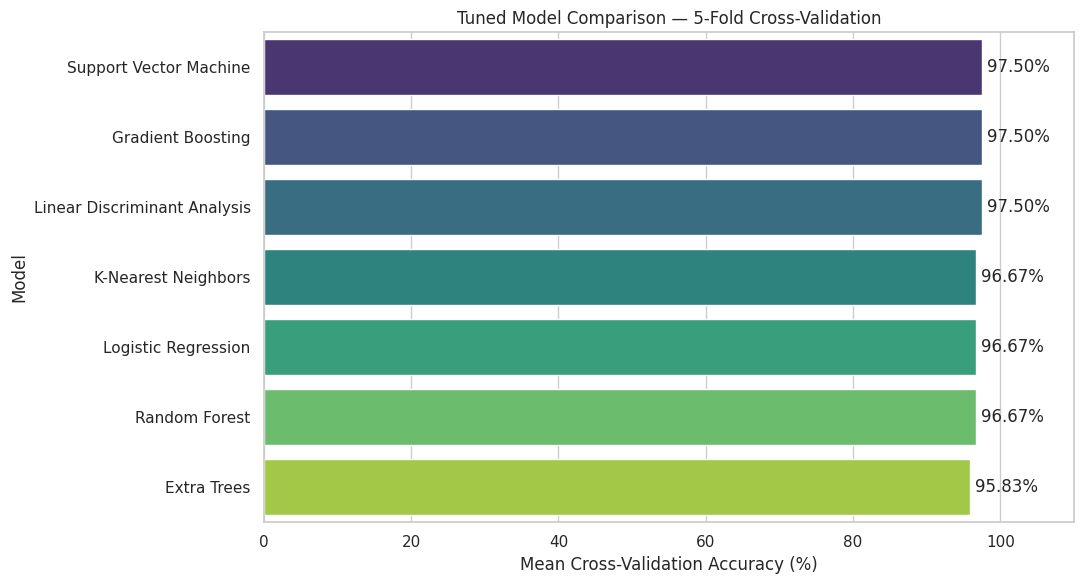

In [28]:
# Rank models using cross-validation performance

cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by=["Best CV Accuracy (%)", "CV Standard Deviation (%)"],
    ascending=[False, True]
).reset_index(drop=True)

display(
    cv_df.style.format({
        "Best CV Accuracy (%)": "{:.2f}%",
        "CV Standard Deviation (%)": "{:.2f}%"
    })
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=cv_df,
    x="Best CV Accuracy (%)",
    y="Model",
    hue="Model",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4)

plt.title("Tuned Model Comparison — 5-Fold Cross-Validation")
plt.xlabel("Mean Cross-Validation Accuracy (%)")
plt.ylabel("Model")
plt.xlim(0, 110)
plt.tight_layout()
plt.show()

**Evaluate models on the held-out test set**

In [29]:
# Evaluate the tuned models on the test set

test_predictions = {}
test_results = []

for model_name, model in best_estimators.items():

    y_pred = model.predict(X_test)
    test_predictions[model_name] = y_pred

    test_results.append({
        "Model": model_name,
        "Test Accuracy (%)": accuracy_score(
            y_test, y_pred
        ) * 100,
        "Macro Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Macro F1-Score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Weighted F1-Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

test_df = pd.DataFrame(test_results)

test_df = test_df.sort_values(
    by=["Test Accuracy (%)", "Macro F1-Score"],
    ascending=False
).reset_index(drop=True)

display(test_df.round(4))

,Model,Test Accuracy (%),Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score
0,Logistic Regression,100.0000,1.0000,1.0000,1.0000,1.0000
1,Linear Discriminant Analysis,100.0000,1.0000,1.0000,1.0000,1.0000
2,Random Forest,96.6667,0.9697,0.9667,0.9666,0.9666
3,Extra Trees,96.6667,0.9697,0.9667,0.9666,0.9666
4,Gradient Boosting,96.6667,0.9697,0.9667,0.9666,0.9666
5,Support Vector Machine,93.3333,0.9333,0.9333,0.9333,0.9333
6,K-Nearest Neighbors,93.3333,0.9444,0.9333,0.9327,0.9327


**Confusion matrices**

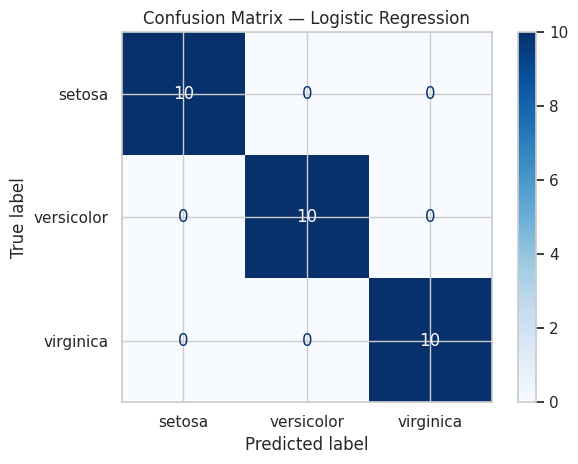

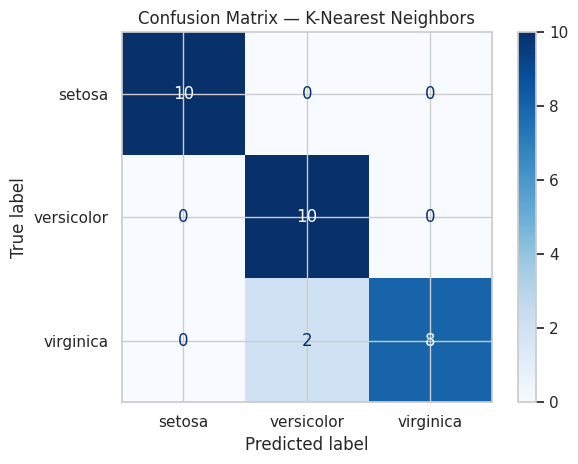

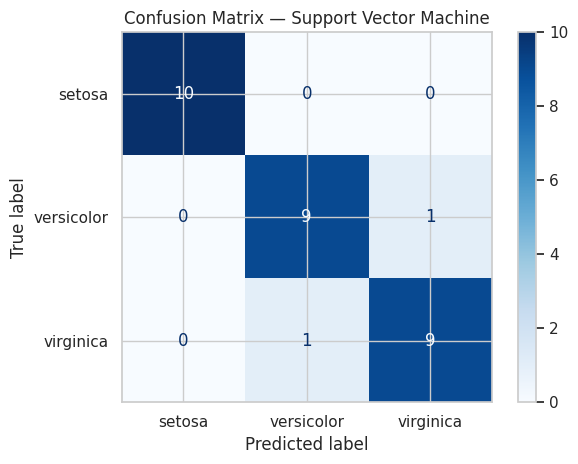

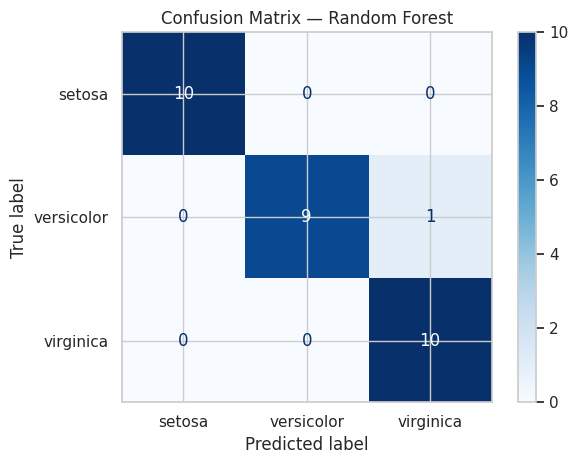

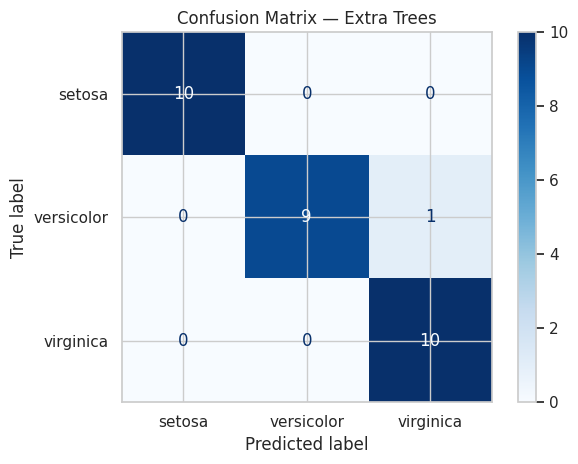

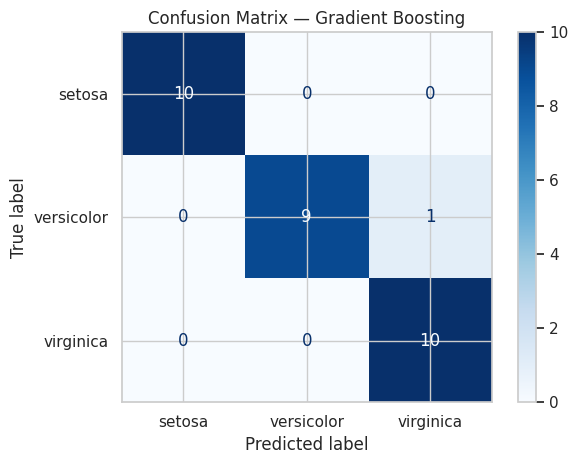

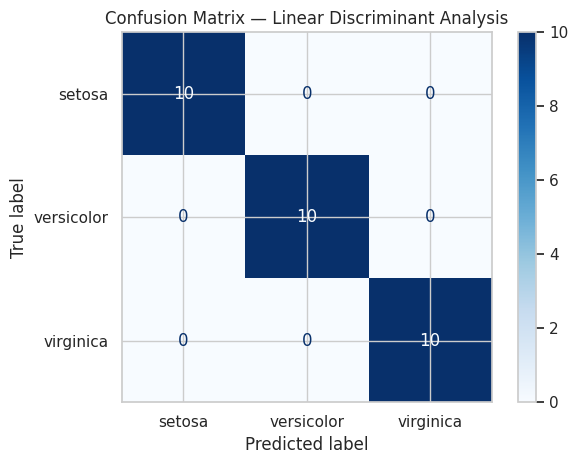

In [30]:
# Visualize the test predictions of every tuned model

for model_name, y_pred in test_predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1, 2]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=iris.target_names
    )

    disp.plot(cmap="Blues", values_format="d")

    plt.title(f"Confusion Matrix — {model_name}")
    plt.tight_layout()
    plt.show()

**Select the model using validation results**

In [35]:
# Compare cross-validation results for the top test-set models

display(
    cv_df[
        cv_df["Model"].isin([
            "Logistic Regression",
            "Linear Discriminant Analysis",
            "Support Vector Machine"
        ])
    ][[
        "Model",
        "Best CV Accuracy (%)",
        "CV Standard Deviation (%)"
    ]].sort_values(
        by="Best CV Accuracy (%)",
        ascending=False
    ).round(2)
)

,Model,Best CV Accuracy (%),CV Standard Deviation (%)
0,Support Vector Machine,97.50,2.04
2,Linear Discriminant Analysis,97.50,3.33
4,Logistic Regression,96.67,3.12


In [31]:
# Select based on cross-validation accuracy.
# If tied, prefer the lower cross-validation standard deviation.

best_row = cv_df.iloc[0]
best_model_name = best_row["Model"]
best_model = best_estimators[best_model_name]

best_predictions = test_predictions[best_model_name]

print("=" * 60)
print("SELECTED MODEL")
print("=" * 60)

print("Model:", best_model_name)
print(
    f"Mean CV accuracy: "
    f"{best_row['Best CV Accuracy (%)']:.2f}%"
)
print(
    f"CV standard deviation: "
    f"{best_row['CV Standard Deviation (%)']:.2f}%"
)

print(
    f"Test accuracy: "
    f"{accuracy_score(y_test, best_predictions) * 100:.2f}%"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        best_predictions,
        target_names=iris.target_names,
        zero_division=0
    )
)

print("Confusion Matrix:")
print(confusion_matrix(y_test, best_predictions))

SELECTED MODEL
Model: Support Vector Machine
Mean CV accuracy: 97.50%
CV standard deviation: 2.04%
Test accuracy: 93.33%

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


**Test a sample flower**

In [32]:
# Predict the species for a sample flower

sample_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

predicted_class = best_model.predict(sample_flower)[0]

print("Sample measurements:")
display(sample_flower)

print("Predicted species:", iris.target_names[predicted_class])

Sample measurements:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


Predicted species: setosa


## Best-Performing Model and Justification

Based on the stratified five-fold cross-validation results, **Support Vector Machine (SVM)** was selected as the final model for this experiment.

### Cross-Validation Performance

- **Mean cross-validation accuracy:** 97.50%
- **Cross-validation standard deviation:** 2.04%

SVM achieved the highest mean cross-validation accuracy, tied with Linear Discriminant Analysis (LDA). However, SVM had a lower cross-validation standard deviation than LDA, suggesting less variation in its scores across the validation folds.

### Test-Set Performance

- **Test accuracy:** 93.33%
- **Macro precision:** 0.93
- **Macro recall:** 0.93
- **Macro F1-score:** 0.93

The confusion matrix showed that SVM correctly classified all 10 Setosa samples. It correctly classified 9 out of 10 Versicolor samples and 9 out of 10 Virginica samples. One Versicolor sample was misclassified as Virginica, and one Virginica sample was misclassified as Versicolor.

### Comparison with Other Models

Linear Discriminant Analysis and Logistic Regression achieved 100% test accuracy in this experiment. However, their cross-validation results differed: LDA achieved a mean of 97.50% with a standard deviation of 3.33%, while Logistic Regression achieved a mean of 96.67% with a standard deviation of 3.12%.

SVM was selected based on its strong mean cross-validation performance and comparatively lower variation among these three models. This selection does not establish that SVM is always superior; the test-set results show that LDA and Logistic Regression also performed very well.

**Conclusion:** SVM was selected using cross-validation performance, achieving a mean accuracy of 97.50% and a test accuracy of 93.33%.

**Final Conclusion**


## Conclusion

The Iris Flower Classification project applied machine-learning techniques to classify Iris flowers into Setosa, Versicolor, and Virginica using four physical measurements.

Exploratory Data Analysis included checking the dataset structure, data types, missing values, descriptive statistics, feature distributions, and correlations. Pairplots and box plots helped identify differences between species.

Seven classification algorithms were compared, and hyperparameter tuning was performed using GridSearchCV with stratified five-fold cross-validation. Support Vector Machine was selected based on its mean cross-validation accuracy of **97.50%** and cross-validation standard deviation of **2.04%**.

On the held-out test dataset, SVM achieved **93.33% accuracy**, correctly classifying 28 out of 30 samples. Logistic Regression and Linear Discriminant Analysis achieved 100% test accuracy in this particular split, demonstrating that different models can perform differently across validation and test samples.

This project demonstrates the importance of cross-validation, model comparison, and independent test evaluation when selecting a classification model. The results reflect the observed experiment rather than assuming that perfect accuracy will generalize to unseen data.